In [56]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys

# Custom modules
# sys.path.append(r"C:\Users\rjlea\PycharmProjects\TaskSpecificNeuralMechanismsShapeOrientationPerception")
from mytools.analysis import get_oei_data
from mytools.dframe_tools import custom_sort

# Model components
from components.general_functions import get_condcombos
from components.run import mocs_task, run
from components.population_code import Params, Tiling, gen_population_code

In [57]:
def set_params(cond_dicty, cardinal_idx, oblique_idx):
    # sets dictys of params for cardinal and oblique populations
    c_dicty = {}
    o_dicty = {}
    for i_param in cond_dicty:
        if not isinstance(cond_dicty[i_param], list):
            continue
        c_dicty[i_param] = cond_dicty[i_param][cardinal_idx]
        o_dicty[i_param] = cond_dicty[i_param][oblique_idx]
    return Params(c_dicty), Params(o_dicty)

In [58]:
'''
Settings
'''
# Script settings (multi processing uses high CPU - used in main script)
run_type = 'loop'  # 'single' or 'loop' or 'multi_proc' 

# Run information
run_tasks = ['con_det', 'ori_dis']  # ['con_det', 'ori_dis']
run_ori_stds = [0, 45]
run_contrasts = [100]
n_level_reps = 1000
decoders_ori = ['ML', 'PV', 'WTA']  # ['WTA', 'PV', 'ML']
decoders_condet = ['peak', 'sum', 'mag']  # # ['peak', 'sum', 'v_mag', 'distance', 'PV']

In [59]:
'''
Define fixed model parameters
'''
# Response defaults
fixed_params = {
    'noise_type': 'poisson',
    'pref_distrib': 'cos',
    'param_distrib': 'cos',
    'crf_exponent': 2,
    'crf_c50': 24,
    'spont': 3,
}
# Orientation space
orispace = Tiling(-90, 90, step_size=0.05)


In [60]:
'''
Define orientation anisotropies so that cardinal and oblique neurons have different response parameters
'''

# To achieve this, we define the peak value for each parameter
# Let's consider a model with anisotropic orientation bandwidths
cardinal =  Params({
    'n_prefs': 7,  # Defines the number of neurons for each boundary (e.g., from -22.5 to 22.5)
    'fwhm': 25,
    'rmax': 60,
    'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    'n_prefs': 7,
    'fwhm': 50,
    'rmax': 60,
    'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace,
                            g_params={'pooling_q': 6}  # Pooling exponent applies if weighted pooling being used
                            )

Desired propn_cardinal = 0.50
Actual propn_cardinal = 0.43


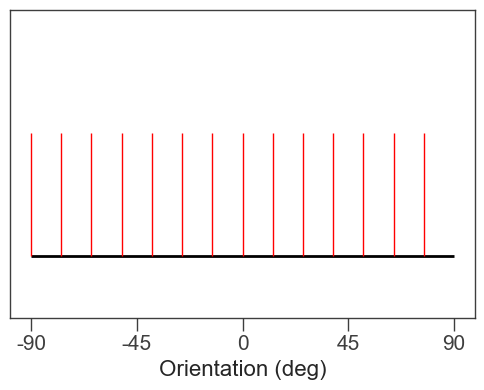

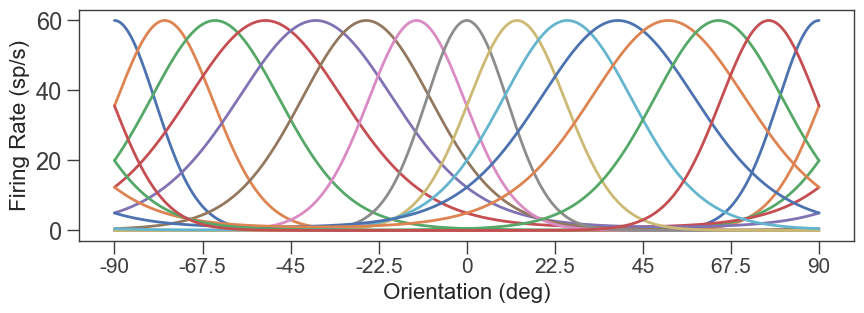

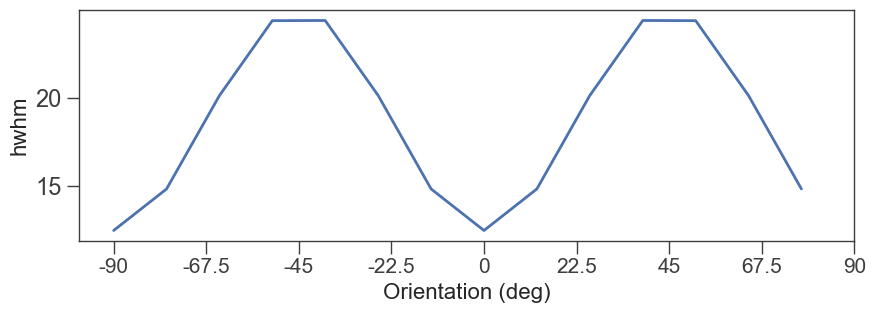

In [61]:
# Show preferences of each neuron
fig, ax = plt.subplots()
ax.hlines(0, xmin=-90, xmax=90, color='black')
ax.vlines(model.prefs, ymin=0, ymax=1, color='red', linewidth=1, zorder=5)
ax.set(xlabel='Orientation (deg)',
       ylim=(-0.5, 2), 
       yticks=[],
       xticks=[-90, -45, 0, 45, 90], xticklabels=[f"{i}" for i in [-90, -45, 0, 45, 90]],
       );

# The tuning curves of each neuron has been set up according to the defined parameters
fig, ax = plt.subplots(figsize=(10, 3))
plt.plot(orispace.tiling, model.tunings.T)
xticks = [-90, -67.5, -45, -22.5, 0, 22.5, 45, 67.5, 90]
ax.set(xlabel='Orientation (deg)', ylabel='Firing Rate (sp/s)',
       xticks=xticks, xticklabels=[f"{i}" for i in xticks],
       );

# We can see how the anisotropic parameters vary across orientation space
fig, ax = plt.subplots(figsize=(10, 3))
plt.plot(orispace.tiling[model.prefs_idx], model.param_distribs['fwhm'] / 2)
ax.set(xlabel='Orientation (deg)', ylabel='hwhm',
       xticks=xticks, xticklabels=[f"{i}" for i in xticks],
       );


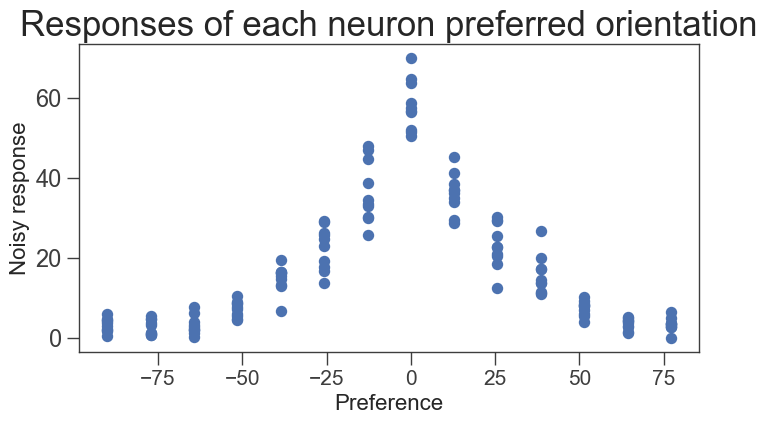

In [62]:
'''
Trial-to-trial model responses 
'''
# On each trial, noise is added to the tuned response for a given orientation
n_reps = 10
noisy_response = model.gen_stim_response(stim_ori=0, stim_con=100, n_reps=n_reps)

# Plot noisy response of all neurons to that orientation for n_repeats
fig, ax = plt.subplots(figsize=(8, 4));
# plt.plot(model.prefs, noisy_response[:, :n_repeats, 0]);

x = np.repeat(model.prefs, n_reps)
y = noisy_response[:, :, 0].ravel()

plt.scatter(x, y)
plt.xlabel("Preference")
plt.ylabel("Noisy response")
plt.title(f"Responses of each neuron preferred orientation")
plt.show()

ax.set(xlabel='Orientation Preference', ylabel='Firing Rate (sp/s)');

Desired propn_cardinal = 0.67
Actual propn_cardinal = 0.69


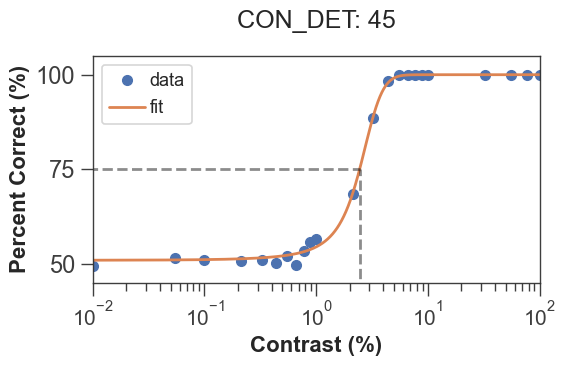

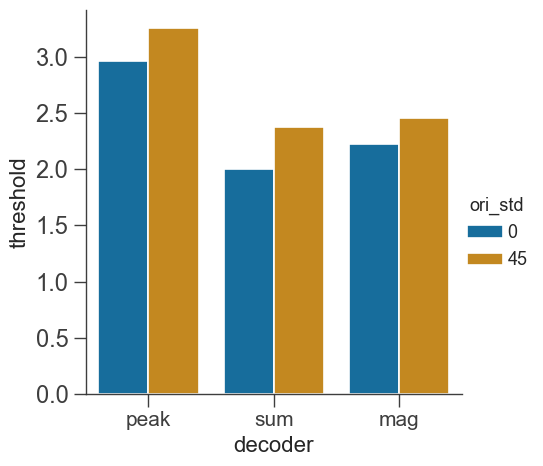

In [63]:
'''
Simulating model performance on contrast-detection task
'''
# Simulations uses method of constant stimuli design

# Step 0 - Define the model parameters (cardinal overrepresentation)
cardinal =  Params({
    # 'n_prefs': 63, 'hwhm': 28.1, 'rmax': 60, 'noise_scale': 1,
    'n_prefs': 60, 'fwhm': 56.2, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    # 'n_prefs': 27, 'hwhm': 28.1, 'rmax': 60, 'noise_scale': 1,
    'n_prefs': 30, 'fwhm': 56.2, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace,
                            g_params={'pooling_q': 6}
                            )

# Step 1 - Define the contrast level of each simulation
levels_contrasts = np.hstack([
    np.linspace(0.01, 0.1, 3),
    np.linspace(0.1, 1, 9),
    np.linspace(1, 10, 9),
    np.linspace(10, 100, 5)]
)  # Cover a wide range of possible performance
levels_contrasts = np.asarray(list(set(levels_contrasts)))  # Remove repeated values

# Step 2 - Run simulation for each standard orientation
condet_data = run(
    task='con_det', experiment=mocs_task, model=model, decoders=decoders_condet, stdoris=[0, 45], 
    contrasts=[None], design='mocs', run_type_=run_type, n_level_reps=1000, 
    _plot_psychometric=True, levels=levels_contrasts,
)

# Plot curve fit to psychometric function to calculate threshold (x value at 75% correct)
fig = sns.catplot(data=condet_data, x='decoder', y='threshold', hue='ori_std', dodge=4, palette='colorblind', kind='bar',
                  );
display(fig)



!!! MAX LIKELIHOOD SHORTCUT FAILED !!!
---Applying ML to full tuned range



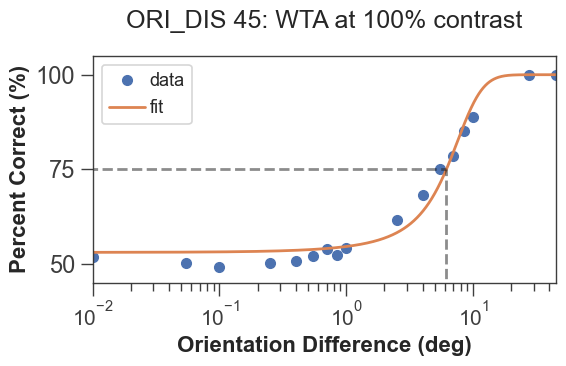

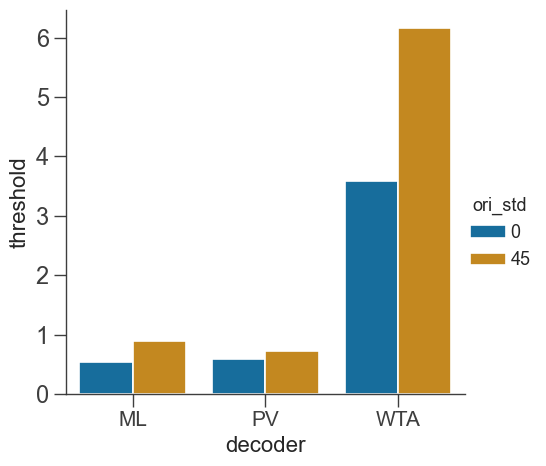

In [64]:
'''
Simulating model performance on orientation-discrimination task
'''

# Step 0 - Define the model parameters (anisotropic bandwidths)
cardinal =  Params({
    'n_prefs': 45, 'fwhm': 56.2 * 0.5, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    'n_prefs': 45, 'fwhm': 56.2, 'rmax': 60, 'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace, 
                            g_params={'pooling_q': 6}
                            )
# Step 1 - Define the orientation differences between standard and comparison stimuli
levels_ori_diff = np.hstack([
    np.linspace(0.01, 0.1, 3),
    np.linspace(0.1, 1, 7),
    np.linspace(1, 10, 7),
    np.linspace(10, 45, 3),
])  # Cover a wide range of possible performance
levels_ori_diff = np.asarray(list(set(levels_ori_diff)))  # Remove repeated values

# Step 2 - Run simulation for each standard orientation
oridis_data = run(
    task='ori_dis', experiment=mocs_task, model=model, decoders=decoders_ori, stdoris=[0, 45], 
    contrasts=[100], design='mocs', run_type_=run_type, n_level_reps=1000, 
    _plot_psychometric=True, levels=levels_ori_diff,
)

# Plot curve fit to psychometric function to calculate threshold (x value at 75% correct)
fig = sns.catplot(data=oridis_data, x='decoder', y='threshold', hue='ori_std', dodge=4, palette='colorblind', kind='bar');
display(fig)

In [72]:
'''
Simulating spatial frequency 
    - Orientation bandwidths that decrease with increasing spatial frequency

Running multiple conditions on CONTRAST DETECTION
    - Code that loops through condition combinations to generate comprehensive simulation dataset
'''

# Bandwidths corresponding to 2, 8, 16 cpd
sf_fwhm = [56.2, 30.0, 22.0]

# Define all possible anisotropies and combinations to simulate 
conditions = {
    'n_prefs': [
        [45, 45],  # Uniform number 
        # [63, 27]  # Cardinal overrepresentation
    ],  
    'fwhm': [
        *[[i, i] for i in sf_fwhm],  # Uniformly decreasing bandwidths with increasing SF
        *[[i * 0.5, i] for i in sf_fwhm]  # Anistropic bandwidths that decrease with increasing SF
    ],
    'noise_scale': [
        [1, 1],  # Uniform noise 
        # [0.5, 1]  # Anisotropic levels of response variability
    ],
    'rmax': [
        [60, 60],  # Uniform rmax
        # [120, 60]  # Anisotropic maximum firing rates
    ]
}

# Generate a list of all simulation conditions
condition_combinations = get_condcombos(conditions)
display(condition_combinations[:5])  # Show example of condition combinations

# Loop through simulation conditions
all_data = []
for idx, cond_combo in enumerate(condition_combinations):
    print(f"Simulation {idx+1}/{len(condition_combinations)}")
    # Set cardinal and oblique parameters
    cardinal =  Params({
        **{k: v[0] for k, v in cond_combo.items()}, 
        **fixed_params
    })
    oblique = Params({
        **{k: v[1] for k, v in cond_combo.items()}, 
        **fixed_params
    })
    
    # Initialise model with these parameters
    model = gen_population_code(cardinal, oblique, orispace, g_params={'pooling_q': 6})
    
    # For this example, we'll simulate performance on the CONTRAST DETECTION task for ONE pooling method
    decoder = 'sum'
    
    # Step 1 - Define the contrast level of each simulation
    levels_contrasts = np.hstack([
        np.linspace(0.01, 0.1, 5),
        np.linspace(0.1, 1, 9),
        np.linspace(1, 10, 9),
        np.linspace(10, 100, 5)]
    )  # Cover a wide range of possible performance
    levels_contrasts = np.asarray(list(set(levels_contrasts)))  # Remove repeated values
    
    # Step 2 - Run simulation for each standard orientation
    condet_sf_data = run(
        task='con_det', experiment=mocs_task, model=model, decoders=[decoder], stdoris=[0, 45], 
        contrasts=[None], design='mocs', run_type_=run_type, n_level_reps=500, 
        _plot_psychometric=False, levels=levels_contrasts,
    )
    # Add condition information to dataset
    for k, v in cond_combo.items():
        condet_sf_data[k] = v
    
    # Number each condition
    condet_sf_data['cond_num'] = idx + 1
    
    # Add to full dataset
    all_data.append(condet_sf_data)


    # ==========================
    # ORIENTATION DISCRIMINATION
    # ==========================
    
    # For this example, we'll simulate performance on the ORIENTATION DISCRIMINATION task for ONE decoder
    decoder = 'WTA'
    
    levels_ori_diff = np.hstack([
        np.linspace(0.01, 0.1, 3),
        np.linspace(0.1, 1, 7),
        np.linspace(1, 10, 7),
        np.linspace(10, 45, 3),
    ])  
    levels_ori_diff = np.asarray(list(set(levels_ori_diff)))  
    
    # Run simulation for each standard orientation
    oridis_sf_data = run(
        task='ori_dis', experiment=mocs_task, model=model, decoders=[decoder], stdoris=[0, 45], 
        contrasts=[100], design='mocs', run_type_=run_type, n_level_reps=500, 
        _plot_psychometric=False, levels=levels_contrasts,
    )
    # Add condition information to dataset
    for k, v in cond_combo.items():
        oridis_sf_data[k] = v
    
    # Number each condition
    oridis_sf_data['cond_num'] = idx + 1
    
    all_data.append(oridis_sf_data)
    
# Combine all data
all_data = pd.concat(all_data)

print(f"\n=====\nResults\n=====\n"
      f"{all_data.head(10)}")

[{'n_prefs': [45, 45],
  'fwhm': [56.2, 56.2],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [30.0, 30.0],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [22.0, 22.0],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [28.1, 56.2],
  'noise_scale': [1, 1],
  'rmax': [60, 60]},
 {'n_prefs': [45, 45],
  'fwhm': [15.0, 30.0],
  'noise_scale': [1, 1],
  'rmax': [60, 60]}]

Simulation 1/6
Simulation 2/6
Simulation 3/6
Simulation 4/6
Simulation 5/6
Simulation 6/6

=====
Results
=====
      task decoder  ori_std contrast  threshold     t_std     slope  s_std  \
0  con_det     sum        0     None   2.223472  0.052518  0.598899    NaN   
1  con_det     sum       45     None   2.120023  0.051769  0.488358    NaN   
0  ori_dis     WTA        0      100   6.116842  0.228714  2.313799    NaN   
1  ori_dis     WTA       45      100   6.008022  0.271395  2.373985    NaN   
0  con_det     sum        0     None   3.067581  0.098816  0.778036    NaN   
1  con_det     sum       45     None   2.956712  0.068317  0.724277    NaN   
0  ori_dis     WTA        0      100   3.668101  0.172464  1.295612    NaN   
1  ori_dis     WTA       45      100   3.495081  0.150451  1.382446    NaN   
0  con_det     sum        0     None   3.496335  0.069647  0.842274    NaN   
1  con_det     sum       45     None   3.712911  0.083957  0.780297    NaN   

  design  n_prefs  fwhm  noise

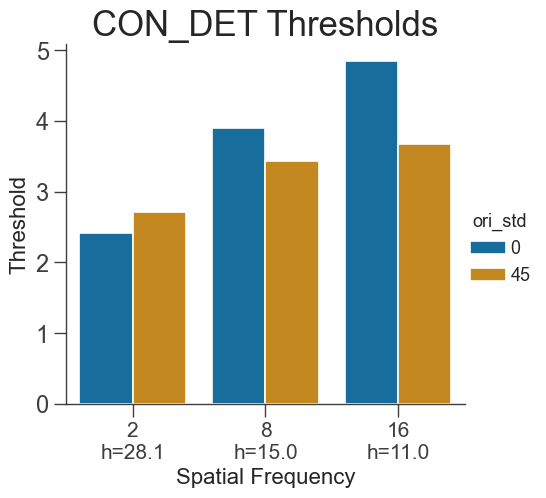

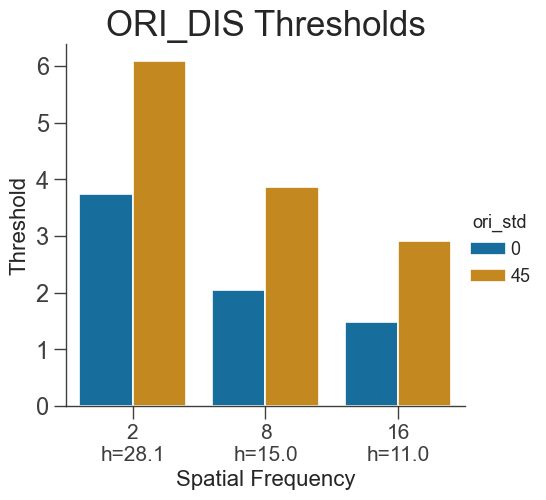

In [76]:
'''
Plot SF data
'''
# Define SF mapping: bandwidth → SF label
sf_map = {56.2: "2\nh=28.1", 30.0: "8\nh=15.0", 22.0: "16\nh=11.0"}

# Prepare a list to collect updated DataFrames
plot_data = []
    
for i_task in ['con_det', 'ori_dis']:
    task_data = all_data[all_data['task'] == i_task]
    
    # Group by condition number
    for cond_num, i_df in task_data.groupby('cond_num'):
        i_df = i_df.copy()  # Copy to avoid issues with pandas 
        
        # Isolate cardinal and oblique parameters for this simulation
        cardinal = i_df[i_df['ori_std'] == 0].iloc[0].to_dict()
        oblique = i_df[i_df['ori_std'] == 45].iloc[0].to_dict()
        
        # Apply SF labels
        sf_label = sf_map.get(oblique['fwhm'])
        if sf_label:
            i_df['sf_label'] = sf_label
        else:
            print(f"Warning: No SF label applied to condition {cond_num} (fwhm = {oblique['fwhm']})")
            
        # Create anisotropy labels to group conditions together
        i_df['proportion_cardinal'] = cardinal['n_prefs'] / i_df['n_prefs'].sum()
        i_df['bandwidth_fraction'] = cardinal['fwhm'] / oblique['fwhm']
        i_df['noise_fraction'] = cardinal['noise_scale'] / oblique['noise_scale']
        i_df['rmax_fraction'] = cardinal['rmax'] / oblique['rmax']
        
        plot_data.append(i_df)

# Concatenate all updated groups
plot_data = pd.concat(plot_data, ignore_index=True)

for i_task in ['con_det', 'ori_dis']:
    cond_data = plot_data[plot_data['task'] == i_task]
    
    # Isolate a condition of interest, e.g., anisotropic bandwidths
    cond_data = cond_data[cond_data['bandwidth_fraction'] == 0.5]
    
    # Plot curve fit to psychometric function to calculate threshold (x value at 75% correct)
    fig = sns.catplot(
        data=cond_data, x='sf_label', y='threshold', hue='ori_std', dodge=4, palette='colorblind', kind='bar', 
    );
    fig.ax.set(xlabel="Spatial Frequency", ylabel="Threshold", title=f"{i_task.upper()} Thresholds")
    display(fig)

C:\Users\rjlea\PycharmProjects\TaskSpecificNeuralMechanismsShapeOrientationPerception\mytools\analysis.py:92: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna('NaN')


' \nIn the final implementation, multiple conditions are overlaid in a single plot for comparison.\n'

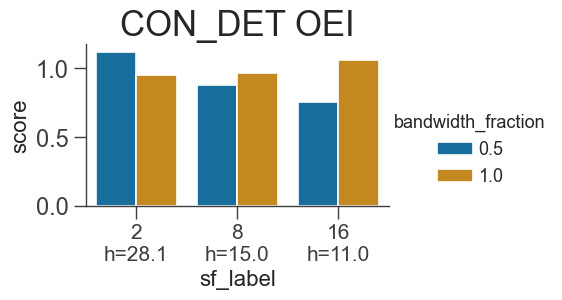

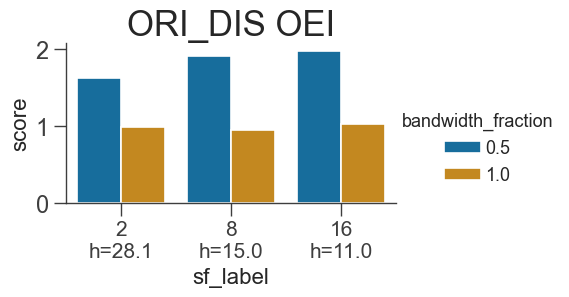

In [90]:
'''
Plotting OEI scores
'''
# Generate OEI scores for each condition combination
cond_list = ['task', 'decoder', 'proportion_cardinal', 'bandwidth_fraction', 'noise_fraction', 'rmax_fraction', 'sf_label', 'cond_num']

for i_task in ['con_det', 'ori_dis']:
    cond_data = plot_data[plot_data['task'] == i_task]
    
    oei_scores = get_oei_data(cond_data, cond_list, ori_label='ori_std', dv='threshold')
    oei_scores = oei_scores[["score", *cond_list]]
    oei_scores = custom_sort(oei_scores, cols=['sf_label'], ordered_labels=[list(sf_map.values())])
    
    # Plot OEI scores for various conditions
    fig = sns.catplot(oei_scores, x="sf_label", y="score", hue="bandwidth_fraction", 
                      dodge=4, palette='colorblind',
                      kind="bar", height=3, aspect=1.5)
    fig.ax.set_title(f"{i_task.upper()} OEI")


''' 
In the final implementation, multiple conditions are overlaid in a single plot for comparison.
'''
